# 02. Medical VLM Pilot Experiments: Language Shift & Visual Reliance

Notebook ini **terhubung langsung** secara modular ke modul-modul skrip Python di folder `scripts/` dan `src/`:
- `src.models.qwen_loader.load_qwen_vl`
- `scripts.run_baseline.run_baseline`
- `scripts.confidence.run_confidence_evaluation`
- `scripts.visual_perturbation.run_visual_perturbation`

Dengan arsitektur modular ini, model **Qwen2.5-VL-3B-Instruct** hanya di-load **satu kali** ke VRAM/RAM, lalu digunakan bersama untuk ketiga eksperimen.

In [1]:
import sys
import os
from pathlib import Path

# Set path ke root project
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Style plotting
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch: {torch.__version__} | CUDA: {torch.cuda.is_available()}")

Project root: C:\.PUSAT\Project\Kuliah\VLM
PyTorch: 2.5.1+cu121 | CUDA: True


## 1. Import Modul Langsung dari File `.py` (`scripts/` & `src/`)

Mengimpor fungsi-fungsi utama dari file `.py` yang telah dimodularisasi.

In [2]:
from src import config
from src.models.qwen_loader import load_qwen_vl
from scripts.run_baseline import run_baseline
from scripts.confidence import run_confidence_evaluation
from scripts.visual_perturbation import run_visual_perturbation

print("Semua modul Python berhasil di-import dari scripts/ dan src/!")

Semua modul Python berhasil di-import dari scripts/ dan src/!


## 2. Load Model & Processor Sekali Saja

Memuat model **Qwen2.5-VL-3B-Instruct** ke memori. Objek `model` dan `processor` ini akan diteruskan langsung ke ketiga fungsi eksperimen tanpa reload ulang.

In [3]:
# Memuat model dan processor (cukup dijalankan 1 kali)
processor, model, target_device = load_qwen_vl()
print(f"Target device: {target_device}")

[ModelLoader] Loading processor from Qwen/Qwen2.5-VL-3B-Instruct...


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.48, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


[ModelLoader] Loading weights for Qwen/Qwen2.5-VL-3B-Instruct on cuda (torch.float16)...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Some parameters are on the meta device because they were offloaded to the cpu.


[ModelLoader] Model ready on device: cuda:0
Target device: cuda:0


## 3. Eksperimen 1: Baseline Zero-Shot Evaluation (`scripts/run_baseline.py`)

Menguji akurasi model dan *flip rate* (seberapa sering model berganti jawaban saat bahasa berubah dari English ke Indonesian).

In [4]:
# Menjalankan fungsi run_baseline langsung dari scripts/run_baseline.py
df_baseline = run_baseline(
    sample_size=10,
    model=model,
    processor=processor,
    target_device=target_device,
    save_output=True
)
df_baseline.head()

[run_baseline] Evaluating on 10 paired questions...


KeyboardInterrupt: 

Akurasi per Bahasa (%):
language
en    60.0
id    10.0
Name: is_correct, dtype: float64


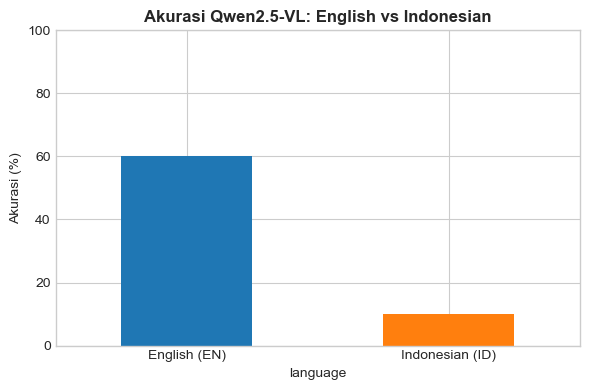

In [ ]:
# Analisis Akurasi EN vs ID
acc_summary = df_baseline.groupby("language")["is_correct"].mean() * 100
print("Akurasi per Bahasa (%):")
print(acc_summary)

plt.figure(figsize=(6, 4))
acc_summary.plot(kind="bar", color=["#1f77b4", "#ff7f0e"])
plt.title("Akurasi Qwen2.5-VL: English vs Indonesian", fontsize=12, fontweight="bold")
plt.ylabel("Akurasi (%)")
plt.ylim(0, 100)
plt.xticks(ticks=[0, 1], labels=["English (EN)", "Indonesian (ID)"], rotation=0)
plt.tight_layout()
plt.show()

## 4. Eksperimen 2: Logprob Confidence Extraction (`scripts/confidence.py`)

Mengekstrak keyakinan probabilitas biner ternormalisasi: $\max(P(\text{YES}), P(\text{NO}))$ dari logit token pertama.

In [ ]:
# Menjalankan fungsi run_confidence_evaluation dari scripts/confidence.py
df_conf = run_confidence_evaluation(
    sample_size=10,
    model=model,
    processor=processor,
    target_device=target_device,
    save_output=True
)
df_conf.head()

[run_confidence_evaluation] Extracting confidence on 10 pairs...
[EN] Pred: NO (Conf: 1.00, GT: NO)


KeyboardInterrupt: 

In [ ]:
# Visualisasi Distribusi Confidence EN vs ID
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_conf, x="language", y="confidence", palette=["#1f77b4", "#ff7f0e"])
plt.title("Distribusi Confidence Model: English vs Indonesian", fontsize=12, fontweight="bold")
plt.xlabel("Bahasa")
plt.ylabel("Normalized Confidence (0.5 - 1.0)")
plt.ylim(0.4, 1.05)
plt.tight_layout()
plt.show()

print("Rata-rata Confidence per Bahasa:")
print(df_conf.groupby("language")["confidence"].mean())

## 5. Eksperimen 3: Counterfactual Visual Perturbation (`scripts/visual_perturbation.py`)

Menguji apakah model benar-benar menggunakan citra radiologi (*Original Image*) dibandingkan citra yang dikosongkan (*Blank Image*).

In [ ]:
# Menjalankan fungsi run_visual_perturbation dari scripts/visual_perturbation.py
df_pert = run_visual_perturbation(
    sample_size=10,
    model=model,
    processor=processor,
    target_device=target_device,
    save_output=True
)
df_pert.head()

In [ ]:
# Visualisasi Sensitivitas Visual: Answer Change Rate & Delta Confidence
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Answer Change Rate
change_rate = df_pert.groupby("language")["answer_changed"].mean() * 100
change_rate.plot(kind="bar", ax=axes[0], color=["#2ca02c", "#d62728"])
axes[0].set_title("Answer Change Rate saat Gambar Dikosongkan (%)", fontweight="bold")
axes[0].set_ylabel("% Jawaban Berubah")
axes[0].set_ylim(0, 100)
axes[0].set_xticklabels(["English (EN)", "Indonesian (ID)"], rotation=0)

# 2. Delta Confidence Drop
sns.barplot(data=df_pert, x="language", y="delta_conf", ax=axes[1], palette=["#2ca02c", "#d62728"])
axes[1].set_title("Rata-rata Penurunan Confidence (|Delta Conf|)", fontweight="bold")
axes[1].set_ylabel("Delta Confidence")
axes[1].set_xticklabels(["English (EN)", "Indonesian (ID)"], rotation=0)

plt.tight_layout()
plt.show()

print("Performa Ketergantungan Visual (Visual Reliance Proxy):")
print(df_pert.groupby("language")[["answer_changed", "delta_conf"]].mean())

## 6. Kesimpulan Pilot & Output Otomatis

Seluruh file output eksperimen tersimpan secara otomatis di folder `outputs/`:
- `outputs/pilot_predictions.csv` (Akurasi baseline)
- `outputs/confidence_results.csv` (Distribusi confidence logprobs)
- `outputs/visual_perturbation_results.csv` (Perubahan jawaban dan delta confidence)

Hasil ini siap disalin ke slide presentasi PPT seminar proposal/skripsi Anda!